# Research questions

Inputs: `results/metrics/<variant>/rq*/` (run_metrics_pipeline.sh). 

Plots: `results/plots/<variant>/rq*_*`. 

In [ ]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from utils import constants as cons
from viz import rq_plots
from viz.figures import save_figure
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [ ]:
# Parameters
SMOKE = False                                  # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # analysis variant: config/variants/<VARIANT>.yaml (main: config/analysis.yaml)
ADJUSTED = True                               # social metrics size-adjusted: <metric>_adj = observed - expected; RQ1 / RQ2 / RQ3 (file names + _adj)
SAVE = True
FORMATS = ['pdf']                              # e.g. ['png', 'pdf']
RQ1_MEASURE = 'omega2'                         # 'shapley_r2' (shares, + residual) | 'omega2' (partial omega^2)
RQ1_METRICS = None                             # None (all) | a family / subgroup ('technical', 'factuality') | [metric keys]
RQ2_VALUE = 'emm'                              # bars: 'deviation' (from the grand mean) | 'emm' (estimated marginal mean)
RQ2_FOREST = 'contrast'                        # forest: 'contrast' (vs the reference value) | 'deviation'
RQ2_METRICS = None                             # heatmap columns: None (all) | a family / subgroup | [metric keys]
RQ3_TECHNICAL = cons.RQ3_TECHNICAL_METRICS        # x axis: summed; refusals, duplicates as 1 - x
RQ3_SOCIAL = cons.RQ3_SOCIAL_METRICS              # y axis: summed (default: the 6 parities)
RQ3_PARETO = False                             # dotted line through the Pareto front
RQ3_GRID = False                               # background grid (False: only the split lines)
RQ3_INSET_COLOR_BY = None                      # absolute + zoom: inset coloured by None (quadrants) | 'access' | 'reasoning' | 'size' | 'origin'
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
from utils import analysis_config
V = analysis_config.notebook_variant(VARIANT, SMOKE)  # folders + config of the variant (configure_variant.py)
METRICS_DIR = Path(V['metrics_dir'])
PLOTS_DIR = Path(V['plots_dir'])
CONFIG = Path(V['config'])
from utils import analysis_config
analysis_config.require_late_reviewed(CONFIG)  # RQs need the late settings (thresholds, valid tags) reviewed
from metrics import summary as _summary
cols = lambda selection: _summary.adjusted_selection(selection, ADJUSTED)   # set names -> <name>_adj if ADJUSTED
RQ1_METRICS, RQ2_METRICS = cols(RQ1_METRICS), cols(RQ2_METRICS)
RQ3_SOCIAL = _summary.adjusted_keys(RQ3_SOCIAL) if ADJUSTED else RQ3_SOCIAL   # parity -> parity_adj

## RQ1. Global influence of each variable

In [ ]:
# Data: partial omega^2 and Shapley R^2 of the model and of every configuration variable, per metric
rq1 = rq_plots.load_rq1(METRICS_DIR / 'rq1')
print(f"{rq1['metric'].nunique()} metrics | {rq1['n_models'].max()} models | {rq1['n_configs'].max():,} configurations")

45 metrics | 43 models | 92,880 configurations


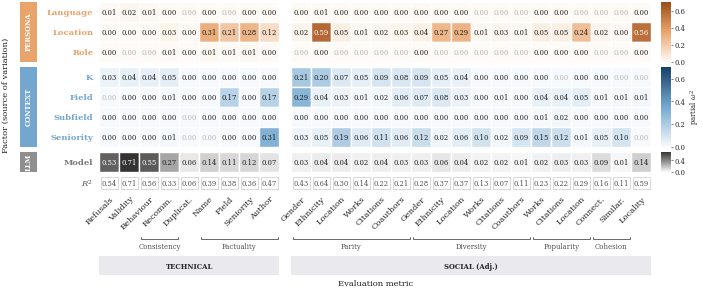

In [ ]:
# Heatmap: RQ1_METRICS (TECHNICAL | SOCIAL); faded = 95% CI includes 0; bottom row: residual (1 - R^2) for
# Shapley R^2, the model's R^2 for omega^2 (fit_row= 'residual' | 'r2' | None to choose)
fig = rq_plots.plot_rq1_heatmap(rq1, RQ1_MEASURE, RQ1_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('heatmap', RQ1_MEASURE, RQ1_METRICS), PLOTS_DIR, FORMATS)

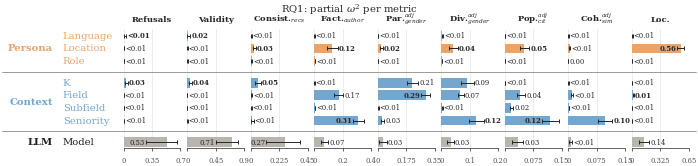

In [ ]:
# Paper figure: rows = prompt composition (persona, context) + LLM, columns = cons.METRIC_COLUMN_SETS['paper']; 95% CI
metric_group = cols('paper')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq1_figure_name('bar', RQ1_MEASURE, metric_group), PLOTS_DIR, FORMATS)

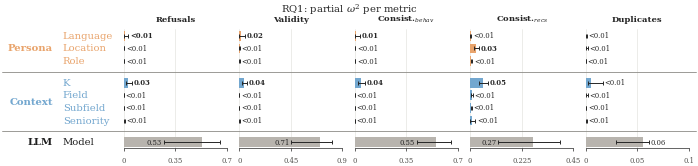

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = cols('technical')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)

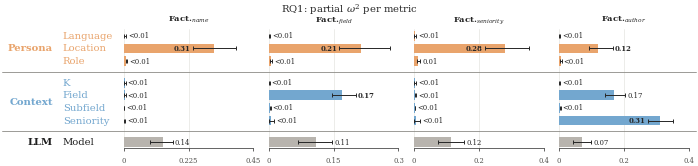

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = cols('factuality')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)

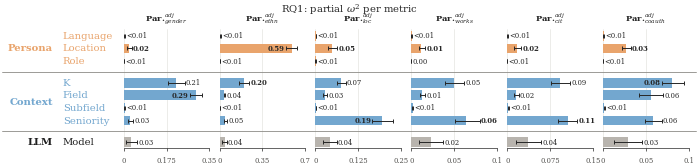

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = cols('parity')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)

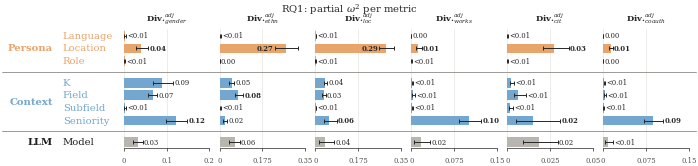

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = cols('diversity')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)

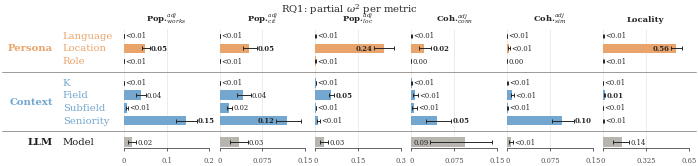

In [ ]:
# Bars: rows = prompt composition (persona, context) + LLM, columns = RQ1_METRICS; 95% CI; bold = largest of its group
metric_group = cols('popularity_cohesion_locality')
fig = rq_plots.plot_rq1(rq1, RQ1_MEASURE, metric_group)

In [ ]:
# Table: RQ1_MEASURE [CI] per variable and metric
rq1.assign(value=rq1.apply(lambda r: f"{r[RQ1_MEASURE]:.3f} [{r[RQ1_MEASURE + '_ci_low']:.3f}, {r[RQ1_MEASURE + '_ci_high']:.3f}]", axis=1)) \
   .pivot(index='variable', columns='metric', values='value')

metric,behaviour_consistency,connectedness,connectedness_adj,diversity_collaboration,diversity_collaboration_adj,diversity_ethnicity,diversity_ethnicity_adj,diversity_gender,diversity_gender_adj,diversity_influence,...,popularity_influence_adj,popularity_location,popularity_location_adj,popularity_productivity,popularity_productivity_adj,recommendation_consistency,refusals,similarity,similarity_adj,validity
variable,,,,,,,,,,,,,,,,,,,,,
field,"0.001 [0.000, 0.002]","0.006 [0.003, 0.012]","0.006 [0.003, 0.012]","0.055 [0.045, 0.066]","0.003 [0.002, 0.005]","0.035 [0.030, 0.044]","0.077 [0.062, 0.096]","0.136 [0.118, 0.157]","0.067 [0.057, 0.079]","0.041 [0.034, 0.049]",...,"0.041 [0.031, 0.054]","0.040 [0.033, 0.048]","0.054 [0.046, 0.065]","0.039 [0.029, 0.050]","0.039 [0.030, 0.051]","0.008 [0.005, 0.013]","0.000 [-0.000, 0.001]","0.009 [0.007, 0.012]","0.009 [0.007, 0.012]","0.001 [0.000, 0.002]"
k,"0.042 [0.021, 0.069]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.088 [0.073, 0.105]","0.002 [0.001, 0.004]","0.015 [0.013, 0.019]","0.049 [0.038, 0.061]","0.018 [0.015, 0.021]","0.090 [0.069, 0.115]","0.083 [0.069, 0.097]",...,"0.000 [-0.000, 0.000]","0.001 [0.000, 0.002]","0.001 [0.000, 0.002]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.055 [0.037, 0.078]","0.031 [0.012, 0.054]","0.000 [-0.000, 0.001]","0.000 [-0.000, 0.001]","0.045 [0.026, 0.070]"
language,"0.010 [0.001, 0.037]","0.000 [-0.000, 0.001]","0.000 [-0.000, 0.001]","0.000 [-0.000, 0.001]","-0.000 [-0.000, 0.000]","0.004 [0.001, 0.009]","0.003 [0.001, 0.007]","0.005 [0.003, 0.009]","0.003 [0.001, 0.006]","0.000 [0.000, 0.001]",...,"0.001 [0.000, 0.001]","0.000 [-0.000, 0.000]","0.000 [-0.000, 0.000]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.002 [0.000, 0.006]","0.007 [0.001, 0.032]","0.000 [-0.000, 0.000]","0.000 [-0.000, 0.000]","0.017 [0.001, 0.050]"
location,"0.001 [0.000, 0.004]","0.022 [0.013, 0.035]","0.022 [0.013, 0.035]","0.010 [0.008, 0.014]","0.013 [0.011, 0.017]","0.283 [0.249, 0.325]","0.270 [0.226, 0.320]","0.034 [0.026, 0.044]","0.041 [0.028, 0.058]","0.031 [0.024, 0.041]",...,"0.051 [0.040, 0.065]","0.239 [0.205, 0.274]","0.240 [0.205, 0.275]","0.050 [0.042, 0.060]","0.050 [0.042, 0.060]","0.026 [0.018, 0.041]","0.002 [0.000, 0.004]","0.003 [0.002, 0.005]","0.003 [0.002, 0.005]","0.003 [0.001, 0.008]"
model,"0.553 [0.421, 0.656]","0.095 [0.032, 0.142]","0.095 [0.032, 0.142]","0.026 [0.016, 0.034]","0.009 [0.003, 0.018]","0.060 [0.032, 0.079]","0.063 [0.039, 0.082]","0.042 [0.027, 0.053]","0.033 [0.021, 0.044]","0.024 [0.014, 0.034]",...,"0.034 [0.019, 0.049]","0.030 [0.015, 0.045]","0.030 [0.015, 0.045]","0.020 [0.011, 0.029]","0.020 [0.011, 0.029]","0.273 [0.123, 0.392]","0.528 [0.271, 0.654]","0.006 [0.003, 0.010]","0.006 [0.003, 0.010]","0.705 [0.454, 0.812]"
role,"0.001 [-0.000, 0.004]","-0.000 [-0.000, 0.000]","-0.000 [-0.000, 0.000]","0.001 [0.000, 0.002]","-0.000 [-0.000, 0.000]","0.001 [0.000, 0.002]","-0.000 [-0.000, 0.000]","0.006 [0.004, 0.010]","0.002 [0.001, 0.004]","0.001 [0.001, 0.002]",...,"0.001 [0.000, 0.001]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.000 [0.000, 0.001]","0.006 [0.003, 0.010]","0.001 [0.000, 0.005]","-0.000 [-0.000, 0.000]","-0.000 [-0.000, 0.000]","0.000 [-0.000, 0.006]"
seniority,"0.001 [0.000, 0.003]","0.045 [0.026, 0.069]","0.045 [0.026, 0.069]","0.006 [0.003, 0.011]","0.088 [0.072, 0.105]","0.000 [-0.000, 0.002]","0.022 [0.015, 0.031]","0.002 [0.000, 0.006]","0.123 [0.098, 0.149]","0.064 [0.048, 0.086]",...,"0.119 [0.098, 0.142]","0.007 [0.003, 0.013]","0.010 [0.005, 0.017]","0.151 [0.125, 0.175]","0.146 [0.122, 0.170]","0.008 [0.001, 0.023]","0.004 [0.001, 0.007]","0.030 [0.020, 0.045]","0.095 [0.078, 0.116]","0.001 [0.000, 0.004]"
subfield,"0.000 [0.000, 0.001]","0.004 [0.002, 0.009]","0.004 [0.002, 0.009]","0.001 [0.001, 0.002]","0.001 [0.000, 0.002]","0.004 [0.002, 0.006]","0.003 [0.002, 0.006]","0.003 [0.002, 0.005]","0.002 [0.001, 0.004]","0.002 [0.001, 0.003

## RQ2. Local influence of each value

In [ ]:
# Data: EMM and deviation from the grand mean of every value of every configuration variable, per metric
rq2 = rq_plots.load_rq2(METRICS_DIR / 'rq2')
print(f"{rq2['metric'].nunique()} metrics | {rq2['n_models'].max()} models | {rq2['n_configs'].max():,} configurations")


45 metrics | 43 models | 92,880 configurations


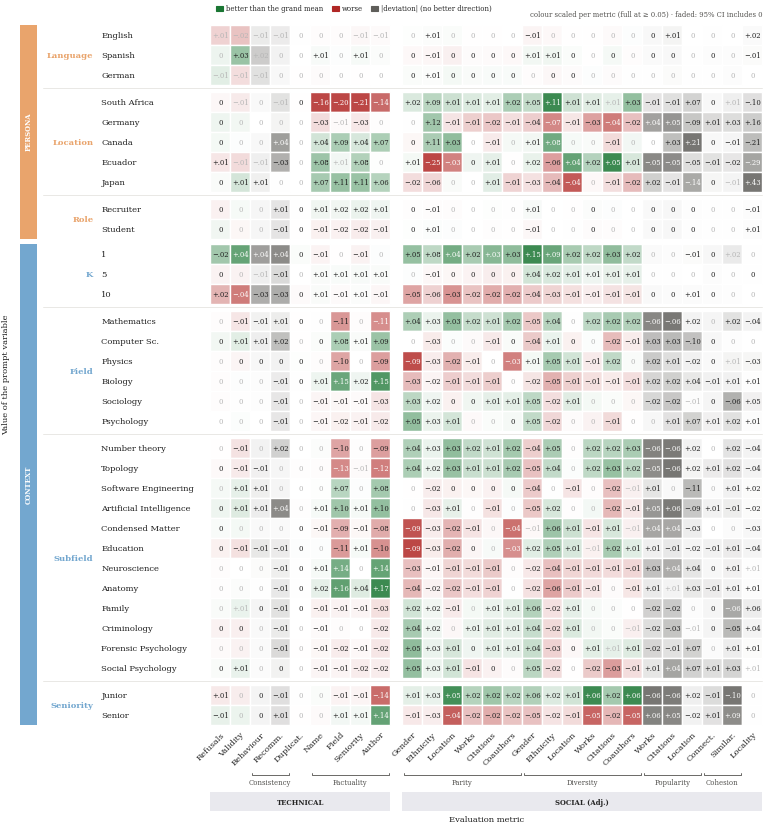

In [ ]:
# Heatmap: deviations, green = better than the grand mean, red = worse, grey = no better direction; faded = CI includes 0
fig = rq_plots.plot_rq2_heatmap(rq2, RQ2_METRICS)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('heatmap', 'deviation', RQ2_METRICS), PLOTS_DIR, FORMATS)


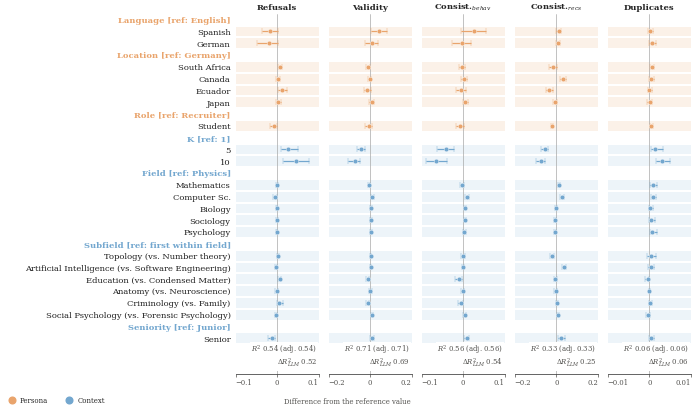

In [ ]:
# Forest: one dot + 95% CI per value, technical metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = cols('technical')
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


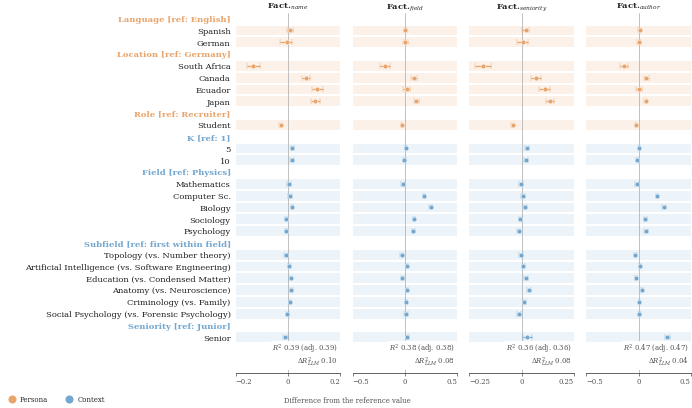

In [ ]:
# Forest: one dot + 95% CI per value, factuality metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = cols('factuality')
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


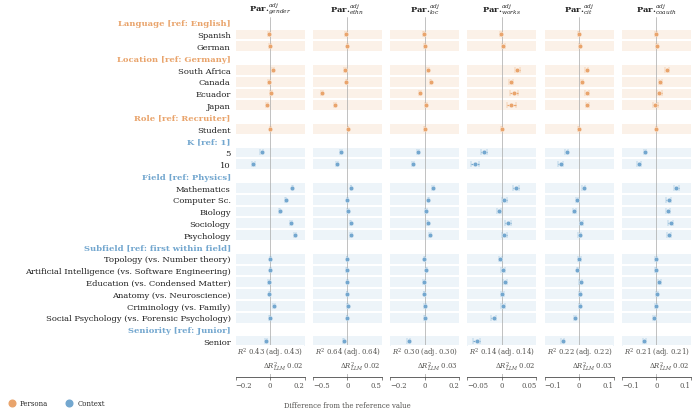

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = cols('parity')
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


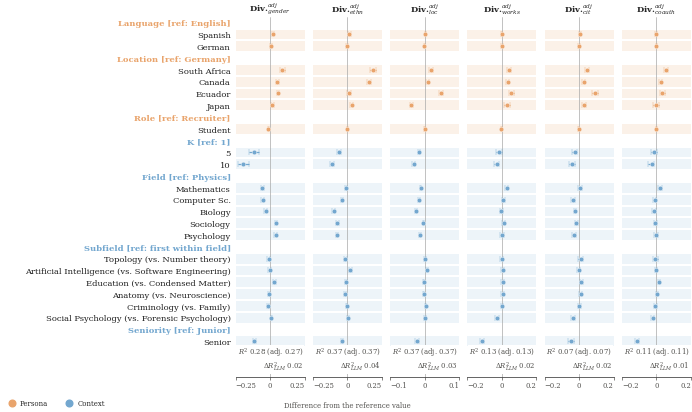

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = cols('diversity')
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


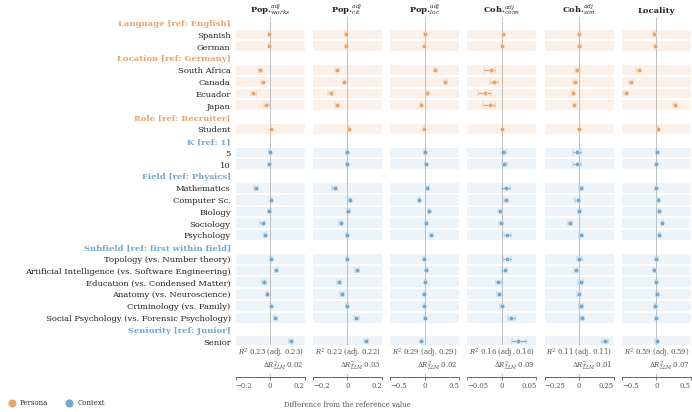

In [ ]:
# Forest: one dot + 95% CI per value, social metrics; R^2, adjusted R^2, Delta R^2 (LLM) per panel
metric_group = cols('popularity_cohesion_locality')
fig = rq_plots.plot_rq2_forest(rq2, RQ2_FOREST, metric_group)
if SAVE:
    save_figure(fig, rq_plots.rq2_figure_name('forest', RQ2_FOREST, metric_group), PLOTS_DIR, FORMATS)


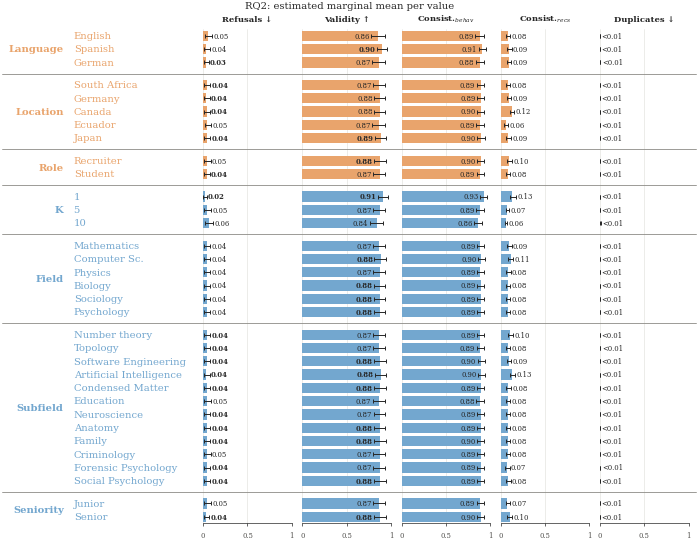

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'technical'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)

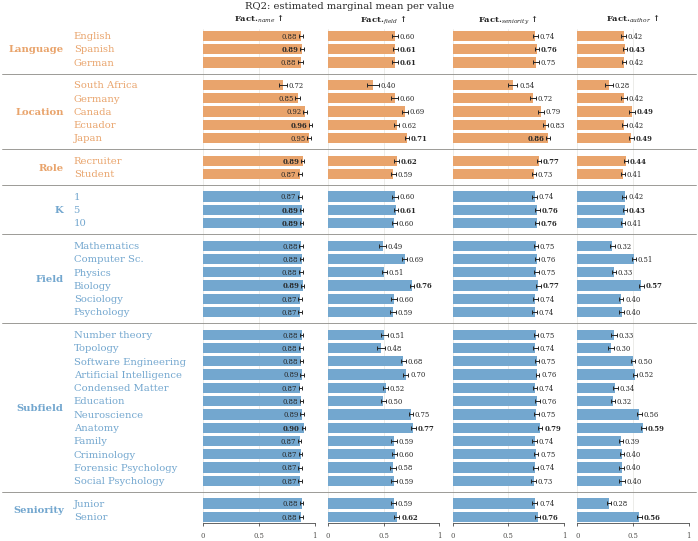

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'factuality'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)

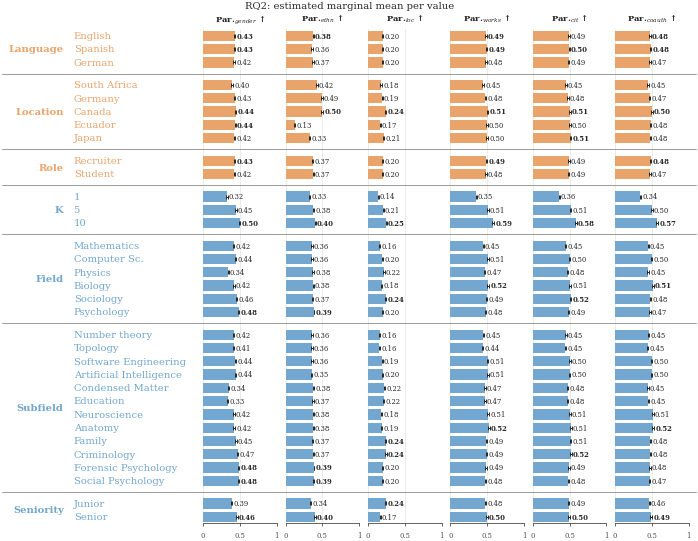

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'parity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)

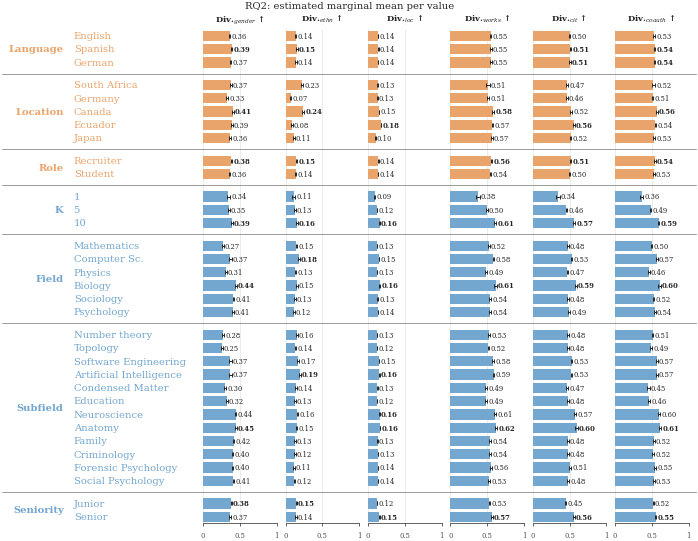

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'diversity'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)

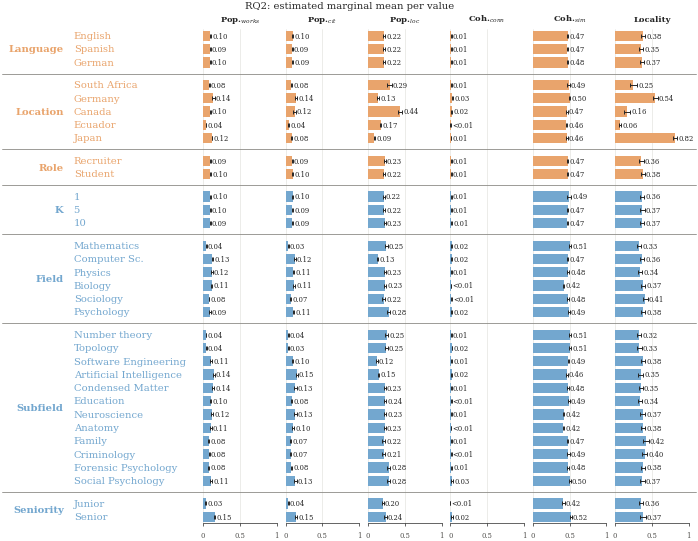

In [ ]:
# Bars: rows = values of the configuration variables, columns = technical metrics; 95% CI
group_metric = 'popularity_cohesion_locality'
fig = rq_plots.plot_rq2(rq2, RQ2_VALUE, group_metric)

## RQ3. Socio-technical trade-off

In [ ]:
# Data: per model, the mean of each metric over its configurations; technical / social score = their sums
from analysis import tradeoff
from metrics import summary
rq3 = tradeoff.model_scores(summary.configuration_table(METRICS_DIR), RQ3_TECHNICAL, RQ3_SOCIAL)
rq3.assign(quadrant_relative=tradeoff.quadrants(rq3, 'relative'), quadrant_absolute=tradeoff.quadrants(rq3, 'absolute'),
           pareto=tradeoff.pareto_front(rq3)).sort_values('technical', ascending=False).round(3).head(5)


,model,validity,refusals,duplicates,factuality_name,factuality_name_field,factuality_name_seniority,factuality_author,parity_gender_adj,parity_ethnicity_adj,...,technical,social,technical_max,social_max,technical_min,social_min,n_missing,quadrant_relative,quadrant_absolute,pareto
3,dolphin-mixtral-8x22b-v2_9-q4_K_M,1.000,1.0,1.000,0.979,0.768,0.911,0.566,-0.016,-0.199,...,6.224,-0.276,7,6,0,-6,0,Q1,Q4,True
4,dolphin-mixtral-8x7b-v2_7-q4_K_M,0.996,1.0,0.995,0.920,0.720,0.848,0.511,-0.020,-0.171,...,5.990,-0.236,7,6,0,-6,0,Q1,Q4,True
27,mistral-small-22b-instruct-2409-q4_K_M,0.999,1.0,1.000,0.936,0.696,0.831,0.481,-0.031,-0.154,...,5.943,-0.307,7,6,0,-6,0,Q4,Q4,False
8,falcon3-7b-instruct-q4_K_M,0.978,1.0,0.999,0.938,0.660,0.844,0.473,-0.035,-0.100,...,5.892,-0.221,7,6,0,-6,0,Q1,Q4,True
11,gemini-2_5-pro,0.998,1.0,1.000,0.929,0.744,0.680,0.496,-0.037,-0.122,...,5.847,-0.464,7,6,0,-6,0,Q4,Q4,False


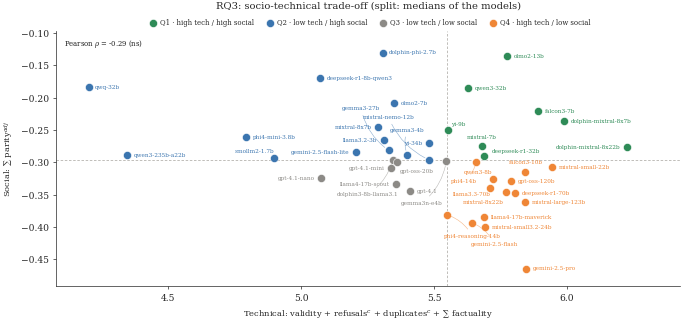

In [ ]:
# Relative: quadrants split at the medians of the models
style = 'relative'
fig = rq_plots.plot_rq3(rq3, style, RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL, grid=RQ3_GRID)

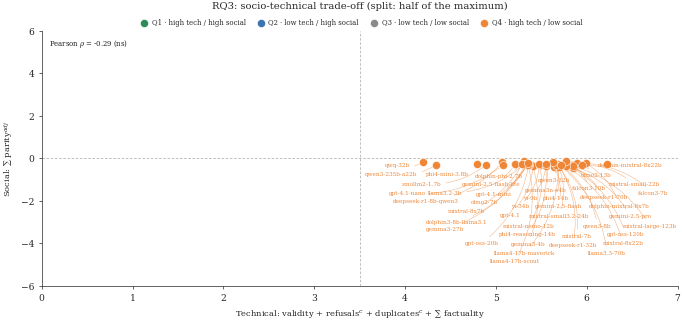

In [ ]:
# Absolute: quadrants split at half of each axis maximum (axes from 0 to the maximum)
style = 'absolute'
fig = rq_plots.plot_rq3(rq3, style, RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL, grid=RQ3_GRID)

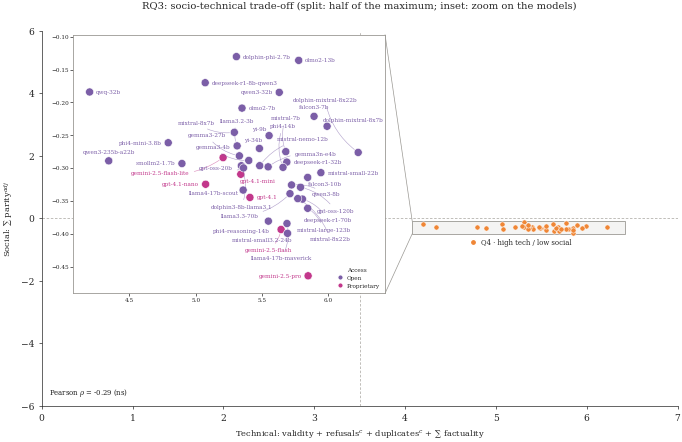

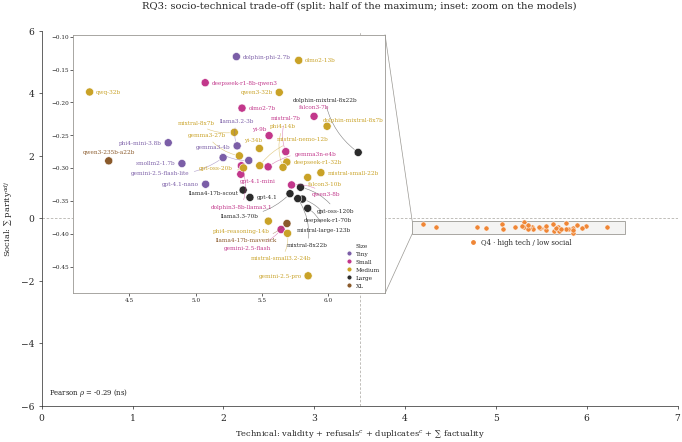

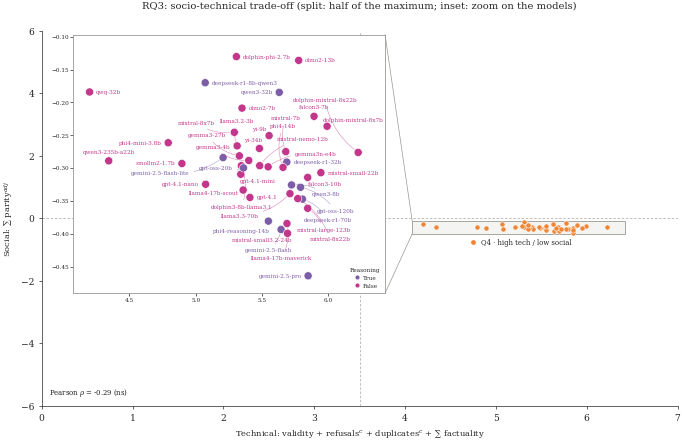

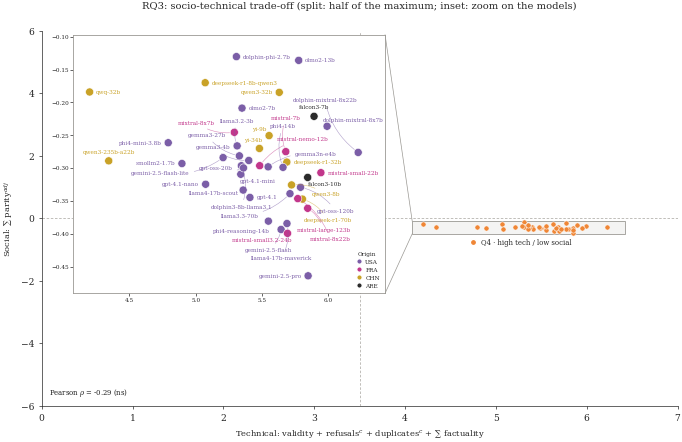

In [ ]:
# Absolute + zoom: the absolute view (points only) with a zoomed, labelled inset on the models
# (RQ3_INSET_COLOR_BY: the inset coloured by a model characteristic; file name + _<characteristic>)
for icb in ['access','size','reasoning','origin']:
    style = 'absolute_inset' + (f'_{icb}' if icb else '')
    fig = rq_plots.plot_rq3_inset(rq3, RQ3_PARETO, RQ3_TECHNICAL, RQ3_SOCIAL, grid=RQ3_GRID, color_by=icb)
    if SAVE and icb == 'access':
        save_figure(fig, rq_plots.rq3_figure_name(style, RQ3_TECHNICAL, RQ3_SOCIAL), PLOTS_DIR, FORMATS)